In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

import spacy
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import torch
from transformers import AutoTokenizer, AutoModel

In [ ]:
df = pd.read_csv("../data/clean_hr_data.csv")

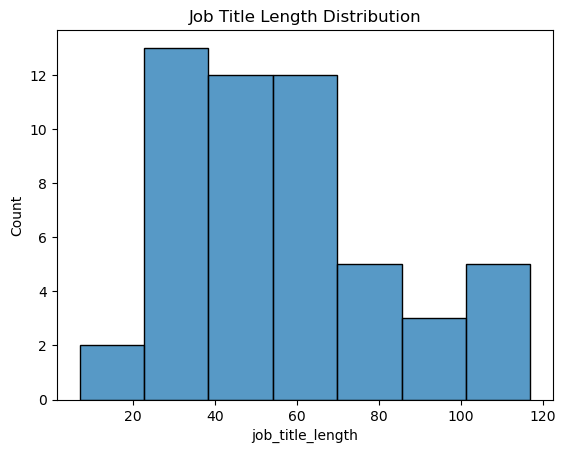

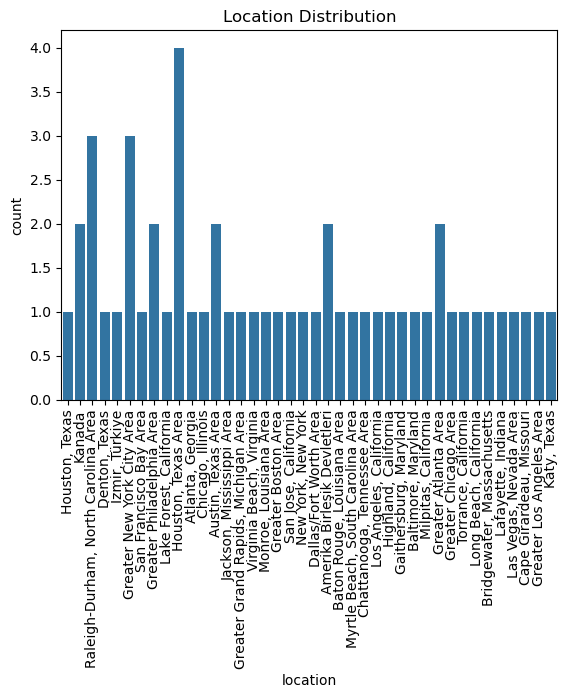

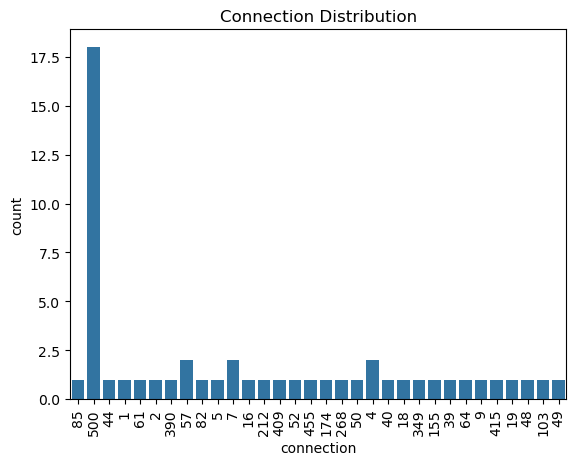

In [9]:
# Count the lengh of the title
df["job_title_length"] = df["job_title"].str.len()
sns.histplot(df["job_title_length"])
plt.title("Job Title Length Distribution")
plt.savefig("../figures/reports/job_title_length.png")
plt.show() 

# Use count plot for location and connection based on 1 variable and count
sns.countplot(
    data = df,
    x = "location"
)
plt.xticks(rotation=90)
plt.title("Location Distribution")
plt.savefig("../figures/reports/location_distribution.png")
plt.show()


sns.countplot(
    data= df,
    x = "connection"
)
plt.title("Connection Distribution")
plt.xticks(rotation=90)
plt.savefig("../figures/reports/ connection_distribution.png")
plt.show()

In [16]:
tokenizer = AutoTokenizer.from_pretrained(
    "intfloat/e5-small-v2"
)

e5 = AutoModel.from_pretrained(
    "intfloat/e5-small-v2"
)


def get_title_vector_e5(text):

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        padding=True
    )

    with torch.no_grad():
        outputs = e5(**inputs)

    # Token embeddings
    token_embeddings = outputs.last_hidden_state

    # Attention mask
    attention_mask = inputs["attention_mask"]

    # Expand mask to same dimensions as embeddings
    mask = attention_mask.unsqueeze(-1).expand(
        token_embeddings.size()
    ).float()

    # Mean pooling
    vector = (token_embeddings * mask).sum(dim=1) / mask.sum(dim=1)

    return vector.squeeze().numpy()


df["e5_for_modeling"] = df["clean_job_title"].apply(
    get_title_vector_e5
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

In [17]:
measure_rank_1 = "aspiring human resources" 
measure_rank_2 =  "seeking human resources"

In [18]:
X_e5 = np.vstack(df["e5_for_modeling"])

y1_vector = get_title_vector_e5(measure_rank_1)
y2_vector = get_title_vector_e5(measure_rank_2)

In [19]:
score_1 = cosine_similarity(
    y1_vector.reshape(1, -1),
    X_e5
)

df["similarity_1_5e"] = score_1.flatten()

df[df["similarity_1_5e"]>0.4][["job_title", "similarity_1_5e"]].sort_values(
    by="similarity_1_5e",
    ascending=False
).head(10)

,job_title,similarity_1_5e
2,Aspiring Human Resources Professional,0.972680
5,Aspiring Human Resources Specialist,0.959037
27,Seeking Human Resources Opportunities,0.931176
72,"Aspiring Human Resources Manager, seeking inte...",0.929253
98,Seeking Human Resources Position,0.917001
26,Aspiring Human Resources Management student se...,0.913397
71,Business Management Major and Aspiring Human R...,0.909651
81,Aspiring Human Resources Professional | An ene...,0.904985
66,"Human Resources, Staffing and Recruiting Profe...",0.898971
75,Aspiring Human Resources Professional | Passio...,0.898286


In [20]:
score_2 = cosine_similarity(
    y2_vector.reshape(1, -1),
    X_e5
)

df["similarity_2_5e"] = score_2.flatten()

df[df["similarity_2_5e"]>0.4][["job_title", "similarity_2_5e"]].sort_values(
    by="similarity_2_5e",
    ascending=False
).head(10)

,job_title,similarity_2_5e
27,Seeking Human Resources Opportunities,0.963449
98,Seeking Human Resources Position,0.960323
72,"Aspiring Human Resources Manager, seeking inte...",0.921329
2,Aspiring Human Resources Professional,0.915903
5,Aspiring Human Resources Specialist,0.915452
9,Seeking Human Resources HRIS and Generalist Po...,0.910678
93,Seeking Human Resources Opportunities. Open t...,0.910152
26,Aspiring Human Resources Management student se...,0.905526
73,Human Resources Professional,0.890702
66,"Human Resources, Staffing and Recruiting Profe...",0.889461


In [21]:
def similarity_hist(var):
    df[var].hist(bins=20)
    plt.xlabel("Cosine similarity")
    plt.ylabel("Number of candidates")
    plt.title("Similarity Score Distribution")
    plt.savefig("../figures/reports/similarity_hist_plot.png")
    plt.show()

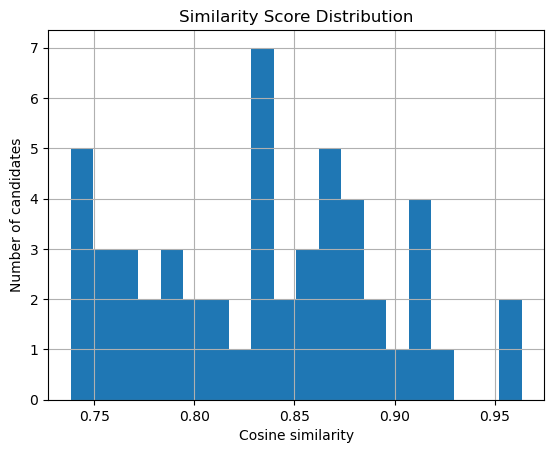

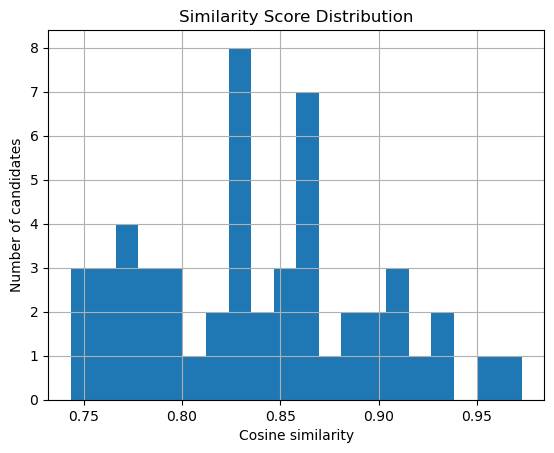

In [22]:
similarity_hist("similarity_2_5e")
similarity_hist("similarity_1_5e")

In [ ]:
def similarity_elbow(var):
    scores = (
        df[var]
        .sort_values(ascending=False)
        .reset_index(drop=True)
    )

    plt.plot(scores)
    plt.xlabel("Candidate rank")
    plt.ylabel("Cosine similarity")
    plt.title("Ranked Similarity Scores")
    plt.savefig("../figures/reports/similarity_elbow_plot.png")
    plt.show()

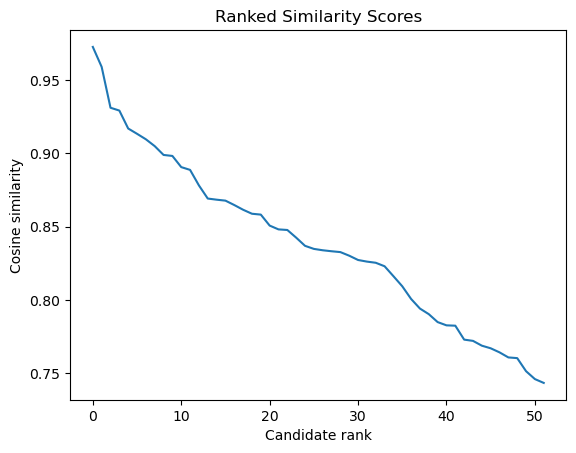

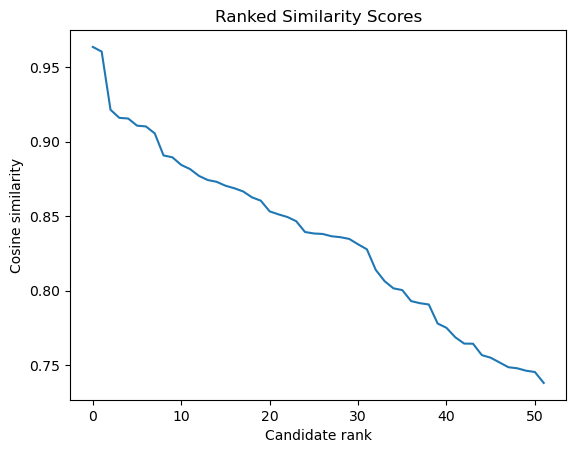

In [28]:
similarity_elbow("similarity_1_5e")
similarity_elbow("similarity_2_5e")